# Crystal-field tomography, 2D toy, flicker-free oracle and robust density
How much the flicker costs the density, and how much a robust (Cauchy) loss recovers without any crystal model. The oracle is the same sample simulated with each slice low-passed below the coarse band, so nothing Bragg scatters. Fits come from `run_oracle.py`, oracle data from `oracle.py`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
from scipy.ndimage import uniform_filter

sys.path.insert(0, str(Path.cwd()))

from quantem.core.visualization.visualization import show_2d

import oracle
import sim2d

## Data

In [2]:
for kind in ["fewAm", "fewA"]:
    sim2d.main(kind)
    oracle.main(kind)
sims = {kind: np.load(f"runs/sim_{kind}.npz") for kind in ["fewAm", "fewA"]}
oracles = {kind: np.load(f"runs/sim_{kind}_nobragg.npz") for kind in ["fewAm", "fewA"]}
fits = {
    kind: {
        "squared error": np.load(f"runs/sm_{kind}_meanonly.npz"),
        "Cauchy": np.load(f"runs/sm_{kind}_meanonly_cauchy1.npz"),
        "oracle data, squared error": np.load(f"runs/sm_{kind}_nobragg_meanonly_tv0.05.npz"),
    }
    for kind in ["fewAm", "fewA"]
}

fewAm: 3011 atoms, 3 grains, 40 Friedel pairs, multislice 1.7 s -> /Users/cophus/Library/CloudStorage/Dropbox/python/quantem/tomography/crystal_field_2d/runs/sim_fewAm.npz


fewAm: no-Bragg data -> runs/sim_fewAm_nobragg.npz


fewA: 3025 atoms, 3 grains, 60 Friedel pairs, multislice 1.7 s -> /Users/cophus/Library/CloudStorage/Dropbox/python/quantem/tomography/crystal_field_2d/runs/sim_fewA.npz


fewA: no-Bragg data -> runs/sim_fewA_nobragg.npz


## Scores
Density correlation with the true mean potential, raw and after a 4-voxel box filter, and the mean density in the particle relative to the truth. Held-out image error is against the data each fit was made on.

In [3]:
for kind, d in sims.items():
    t = d["vbar"]
    part = d["occ"].sum(0) > 0.5
    print(kind)
    for name, r in fits[kind].items():
        v = r["vbar"]
        sc = json.loads(str(r["scores"]))
        print(
            f"  {name:28s} density corr {np.corrcoef(v.ravel(), t.ravel())[0, 1]:.3f}"
            f"  smoothed {np.corrcoef(uniform_filter(v, 4).ravel(), uniform_filter(t, 4).ravel())[0, 1]:.3f}"
            f"  mean density / true {v[part].mean() / t[part].mean():.2f}  held-out {sc['held']:.3f}"
        )

fewAm
  squared error                density corr 0.826  smoothed 0.917  mean density / true 0.81  held-out 0.844
  Cauchy                       density corr 0.888  smoothed 0.948  mean density / true 0.72  held-out 0.843
  oracle data, squared error   density corr 0.898  smoothed 0.939  mean density / true 1.02  held-out 0.096
fewA
  squared error                density corr 0.846  smoothed 0.893  mean density / true 0.64  held-out 1.132
  Cauchy                       density corr 0.878  smoothed 0.906  mean density / true 0.64  held-out 1.147
  oracle data, squared error   density corr 0.915  smoothed 0.943  mean density / true 0.85  held-out 0.118


## All tilts, amorphous cap

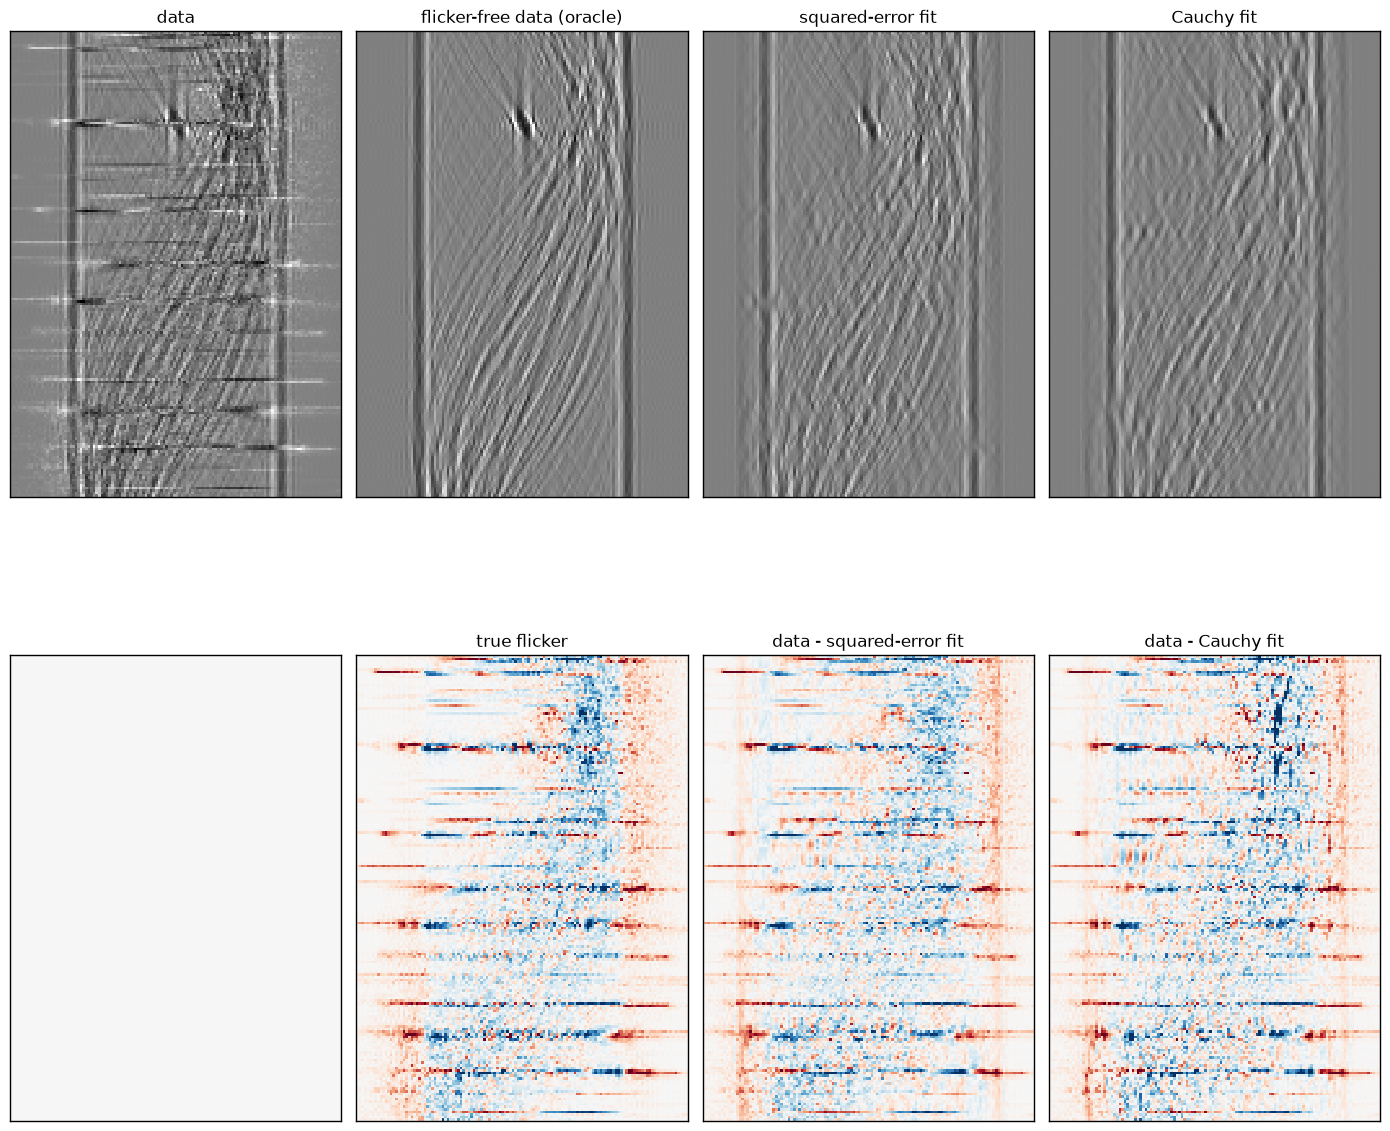

In [4]:
d = sims["fewAm"]
data = d["I_coarse"]
clean = oracles["fewAm"]["I_coarse"]
f = fits["fewAm"]
crop = slice(data.shape[1] // 2 - 64, data.shape[1] // 2 + 64)
norm_int = {"interval_type": "manual", "vmin": 0.2, "vmax": 1.8}
norm_diff = {"interval_type": "centered", "half_range": 0.5}
show_2d(
    [
        [data[:, crop], clean[:, crop], f["squared error"]["pred"][:, crop], f["Cauchy"]["pred"][:, crop]],
        [
            np.zeros_like(data[:, crop]),
            data[:, crop] - clean[:, crop],
            data[:, crop] - f["squared error"]["pred"][:, crop],
            data[:, crop] - f["Cauchy"]["pred"][:, crop],
        ],
    ],
    norm=[[norm_int] * 4, [norm_diff] * 4],
    cmap=[["gray"] * 4, ["RdBu_r"] * 4],
    title=[
        ["data", "flicker-free data (oracle)", "squared-error fit", "Cauchy fit"],
        ["", "true flicker", "data - squared-error fit", "data - Cauchy fit"],
    ],
    axsize=(3.5, 7),
);

## Mean potential

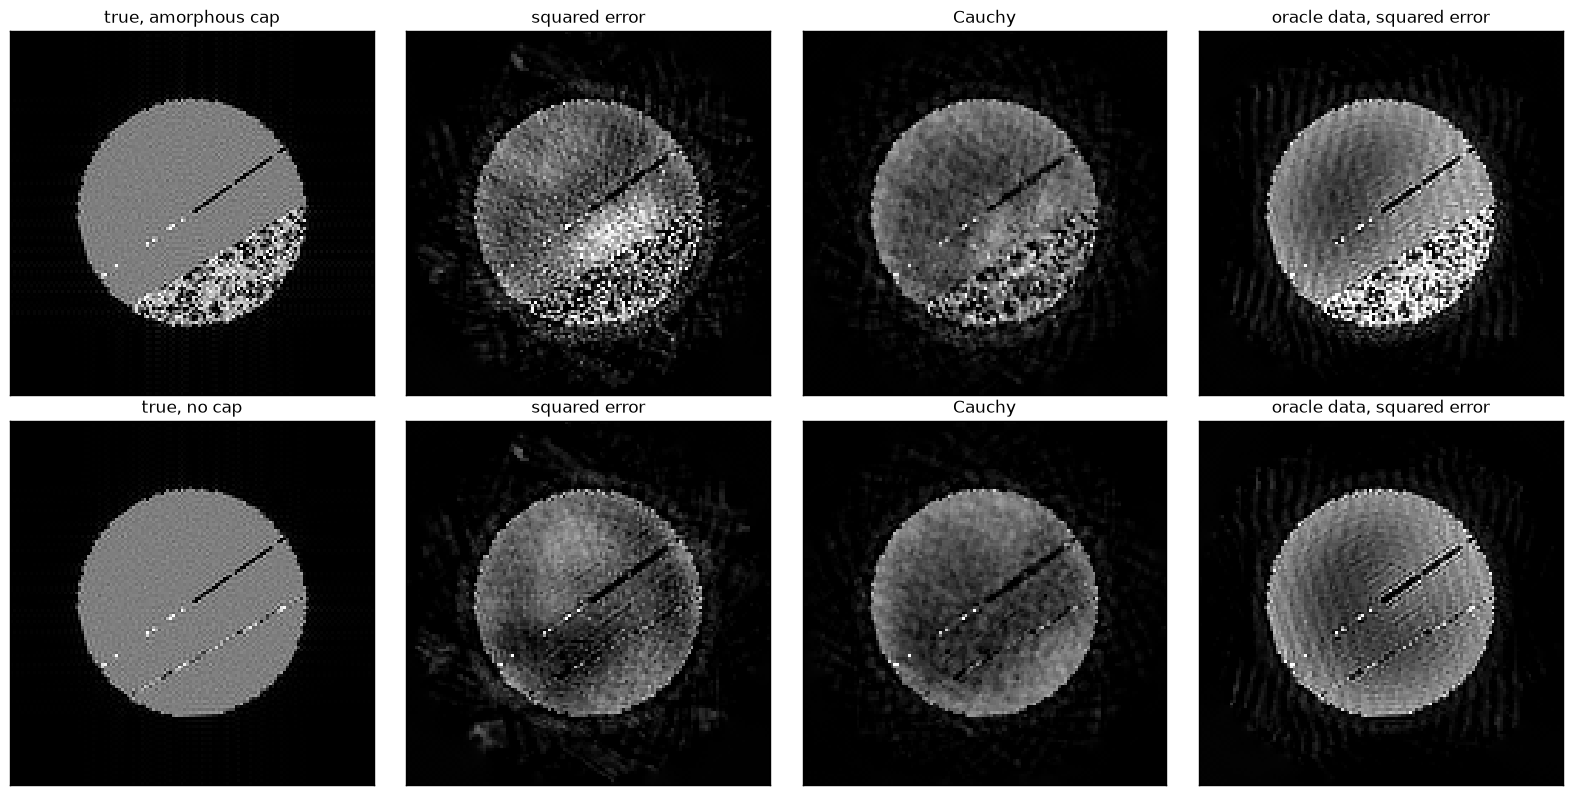

In [5]:
names = list(fits["fewAm"])
show_2d(
    [
        [np.flipud(sims[k]["vbar"].T)] + [np.flipud(fits[k][n]["vbar"].T) for n in names]
        for k in ["fewAm", "fewA"]
    ],
    norm=[[{"interval_type": "manual", "vmin": 0.0, "vmax": 0.04}] * 4] * 2,
    cmap="gray",
    title=[
        ["true, amorphous cap"] + names,
        ["true, no cap"] + names,
    ],
);

## Crystallinity from the discounted residual
The part of each squared residual the Cauchy loss discounts, reconstructed tomographically. Grain 2 of the amorphous-cap sample is amorphous.

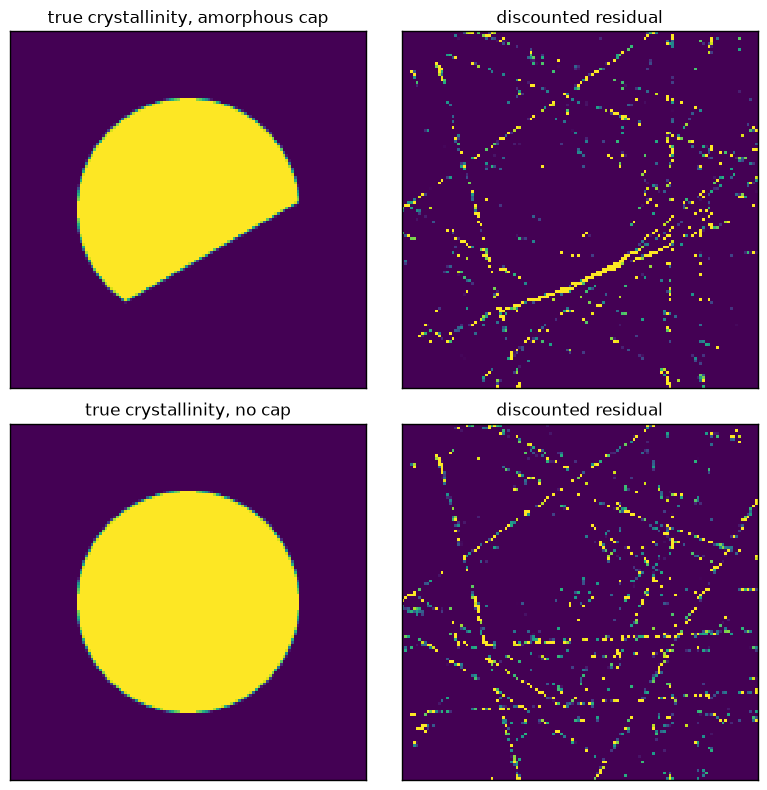

In [6]:
show_2d(
    [
        [np.flipud(sims[k]["cryst"].T), np.flipud(np.load(f"runs/outlier_tomo_{k}_cauchy1.npy").T)]
        for k in ["fewAm", "fewA"]
    ],
    cmap="viridis",
    title=[["true crystallinity, amorphous cap", "discounted residual"], ["true crystallinity, no cap", "discounted residual"]],
);